## Assignments 03

### 1. Global methane levels from 2002

Methane (CH4) is a naturally occurring Greenhouse Gas (GHG), but one whose abundance has been increased substantially above its pre-industrial value by human activities, primarily because of agricultural emissions (e.g., rice production, ruminants) and fossil fuel production and use. A clear annual cycle is largely due to seasonal wetland emissions.

Atmospheric methane abundance is indirectly observed by various satellite instruments. These instruments measure spectrally resolved near-infrared and infrared radiation reflected or emitted by the Earth and its atmosphere. In the measured signal, molecular absorption signatures from methane and constituent gasses can be identified. It is through analysis of those absorption lines in these radiance observations that the averaged methane abundance in the sampled atmospheric column can be determined.

For this problem set, methane levels have been determined by applying several algorithms to different satellite instruments. Download the netCDF4 file (200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc), which contains monthly-averaged methane levels (xch4) in the unit of ppb at each 5° (lon) x 5° (lat) grid over the globe from 2003-01 to 2020-06.

#### 1.1 [5 points] Compute methane climatology for each month, and plot your results in 12 panels.

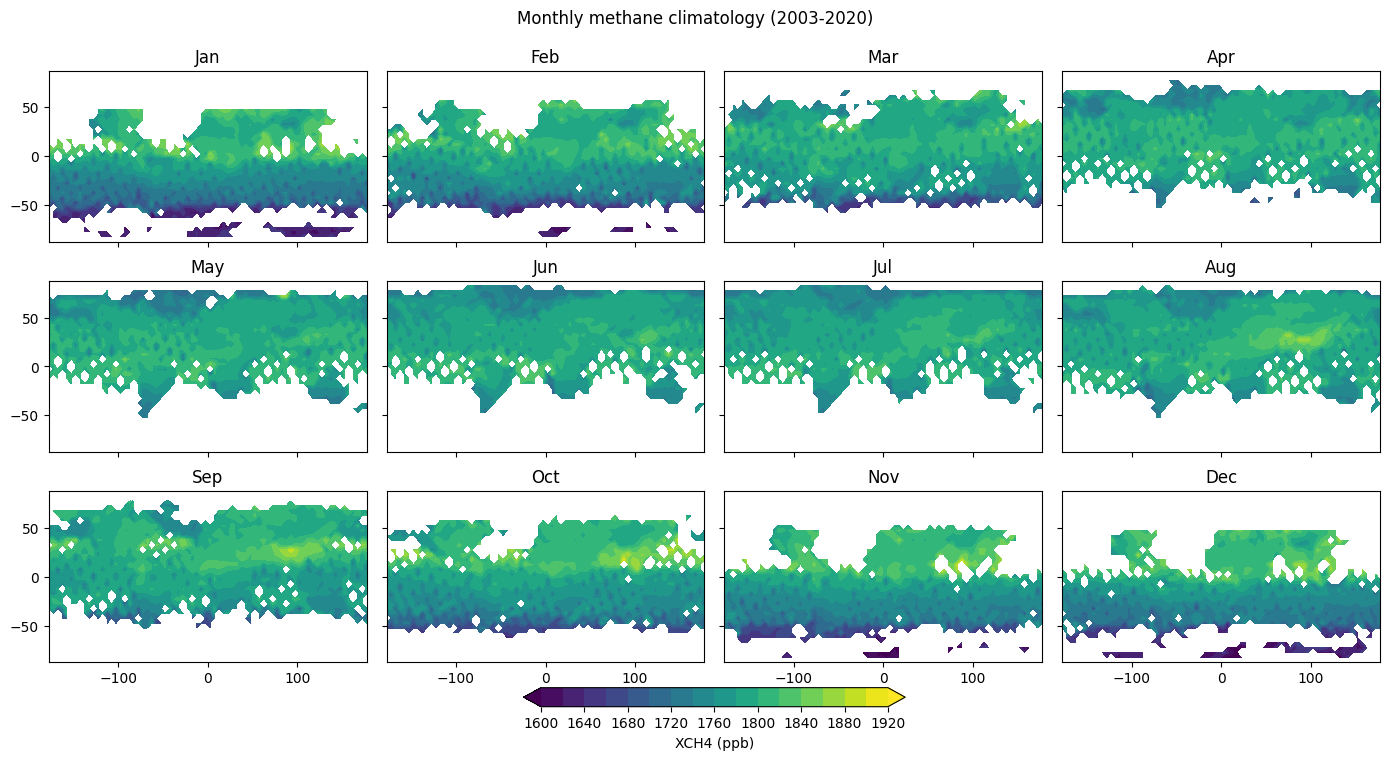

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

ds = xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")
xch4 = ds["xch4"].where(ds["xch4"] < 1e19) * 1e9  # 去掉填充值，换算成 ppb

ch4_clim = xch4.groupby("time.month").mean("time")  # 每个月的多年平均

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(3, 4, figsize=(14, 8))
levels = np.arange(1600, 1921, 20)

for m in range(1, 13):
    ax = axes.flat[m - 1]
    cf = ax.contourf(ds["lon"], ds["lat"], ch4_clim.sel(month=m),
                     levels=levels, cmap="viridis", extend="both")
    ax.set_title(months[m - 1])
    if m <= 8:
        ax.tick_params(labelbottom=False)
    if m % 4 != 1:
        ax.tick_params(labelleft=False)

fig.tight_layout(rect=[0, 0.06, 1, 0.95])
fig.colorbar(cf, ax=axes, orientation="horizontal", fraction=0.03,
             pad=0.04, label="XCH4 (ppb)")
fig.suptitle("Monthly methane climatology (2003-2020)")
plt.show()

#### 1.2 [5 points] Plot globally-averaged methane from 2003-01 to 2020-06 as a time series. Describe your results. Check your plot with this one.

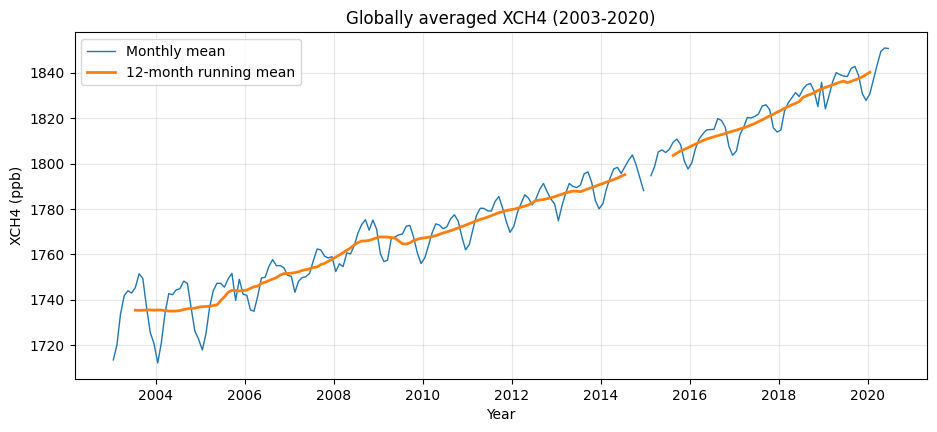

In [2]:
weights = np.cos(np.deg2rad(ds["lat"]))  # 纬度越高，格点代表的面积越小
ch4_global = (xch4 * weights).sum(dim=["lat", "lon"]) / (xch4.notnull() * weights).sum(dim=["lat", "lon"])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(ch4_global["time"], ch4_global.values, linewidth=1, label="Monthly mean")
ax.plot(ch4_global["time"], ch4_global.rolling(time=12, center=True).mean(),
        linewidth=2, label="12-month running mean")
ax.set_title("Globally averaged XCH4 (2003-2020)")
ax.set_xlabel("Year")
ax.set_ylabel("XCH4 (ppb)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

全球平均 CH4 从 2003 年初的约 1713 ppb 持续上升到 2020 年中的约 1851 ppb，17 年多一共增加了约 138 ppb。时间序列上叠加了明显的年循环，用 12 个月滑动平均后可以看到长期上升趋势。

#### 1.3 [5 points] Plot deseasonalized methane levels at point [15°S, 150°W] from 2003-01 to 2020-06 as a time series. Describe your results.

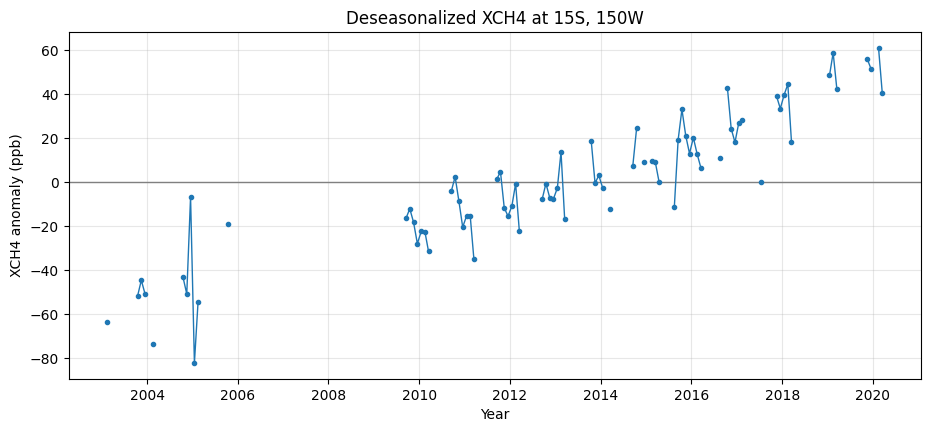

In [15]:
point = xch4.sel(lat=-15, lon=-150, method="nearest")  # 取离[15S, 150W]最近的格点
point_clim = point.groupby("time.month").mean("time")
point_anom = point.groupby("time.month") - point_clim  # 减去各月气候态

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axhline(0, color="gray", linewidth=1)
ax.plot(point_anom["time"], point_anom.values, marker="o", markersize=3, linewidth=1)
ax.set_title("Deseasonalized XCH4 at 15S, 150W")
ax.set_xlabel("Year")
ax.set_ylabel("XCH4 anomaly (ppb)")
ax.grid(alpha=0.3)
plt.show()

在 [15°S, 150°W] 附近，去掉季节循环后的 CH4 从 2003 年的约 1700 ppb 上升到 2020 年的约 1822 ppb，说明该点的甲烷浓度也在增加。由于卫星反演缺测较多，这个格点只有 77 个有效月份，曲线不连续，部分时段的年际起伏需要谨慎解释。

### 2. Niño 3.4 index

The Niño 3.4 anomalies may be thought of as representing the average equatorial sea surface temperatures (SSTs) across the Pacific from about the dateline to the South American coast (5N-5S, 170W-120W). The Niño 3.4 index typically uses a 3-month running mean, and El Niño or La Niña events are defined when the Niño 3.4 SSTs exceed +/- 0.5°C for a period of 5 months or more. Check Equatorial Pacific Sea Surface Temperatures for more about the Niño 3.4 index.

In this problem set, you will use the sea surface temperature (SST) data from NOAA. Download the netCDF4 file (NOAA_NCDC_ERSST_v3b_SST.nc).

#### 1.1 [10 points] Compute monthly climatology for SST from Niño 3.4 region, and subtract climatology from SST time series to obtain anomalies.

In [4]:
ds_sst = xr.open_dataset("NOAA_NCDC_ERSST_v3b_SST.nc")
nino34 = ds_sst["sst"].sel(lat=slice(-5, 5), lon=slice(190, 240)).mean(dim=["lat", "lon"])  # 5S-5N, 170W-120W
nino34_clim = nino34.groupby("time.month").mean("time")  # 各月气候态
nino34_anom = nino34.groupby("time.month") - nino34_clim  # 逐月距平

print(nino34_clim.values.round(2))

[26.57 26.74 27.24 27.69 27.8  27.6  27.2  26.82 26.74 26.72 26.69 26.61]


#### 1.2 [10 points] Visualize the computed Niño 3.4 index. Your plot should look similar to this one.


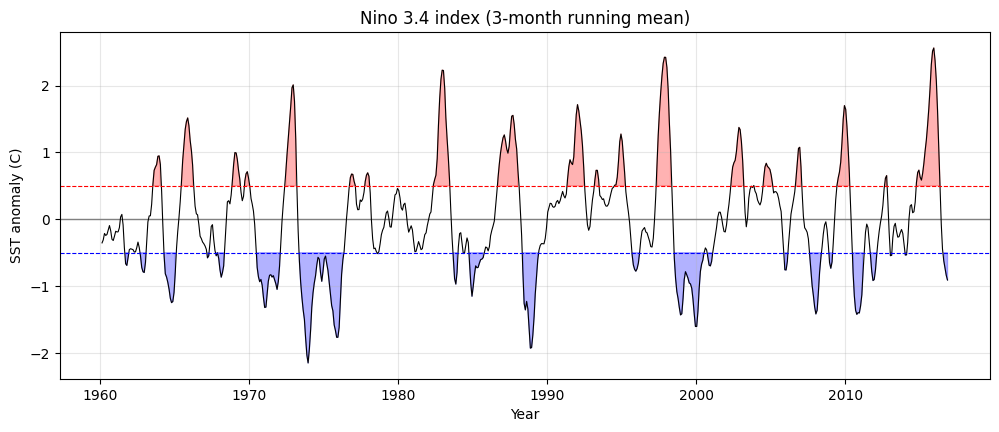

In [14]:
nino34_3month = nino34_anom.rolling(time=3, center=True).mean()  # 3个月滑动平均

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.axhline(0, color="gray", linewidth=1)
ax.plot(nino34_3month["time"], nino34_3month.values, color="black", linewidth=0.8)
ax.fill_between(nino34_3month["time"], nino34_3month.values, 0.5,
                where=nino34_3month.values >= 0.5, color="red", alpha=0.3)
ax.fill_between(nino34_3month["time"], nino34_3month.values, -0.5,
                where=nino34_3month.values <= -0.5, color="blue", alpha=0.3)
ax.axhline(0.5, color="red", linestyle="--", linewidth=0.8)
ax.axhline(-0.5, color="blue", linestyle="--", linewidth=0.8)
ax.set_title("Nino 3.4 index (3-month running mean)")
ax.set_xlabel("Year")
ax.set_ylabel("SST anomaly (C)")
ax.grid(alpha=0.3)
plt.show()

图中 1997/98 和 2015/16 年的 El Niño 事件最强，3 个月滑动平均最高分别约为 2.4°C 和 2.6°C；1973/74 年的 La Niña 最明显，最低约为 -2.1°C。2010/11 年也有一次较强的 La Niña，最低约 -1.4°C。

### 3. Explore a netCDF dataset

Browse the NASA’s Goddard Earth Sciences Data and Information Services Center (GES DISC) website. Search and download a dataset you are interested in. You are also welcome to use data from your group in this problem set. But the dataset should be in netCDF format, and have temporal information.

本大题使用 AGAGE Adrigole 站的 N2O 观测数据（agage-ale-gcmd_adr_n2o_20260716.nc），时间范围为 1978-07 至 1983-12，共 6093 条记录，变量包括 N2O 摩尔分数、测量重复性和采样周期等。

#### 3.1 [5 points] Plot a time series of a certain variable with monthly seasonal cycle removed.

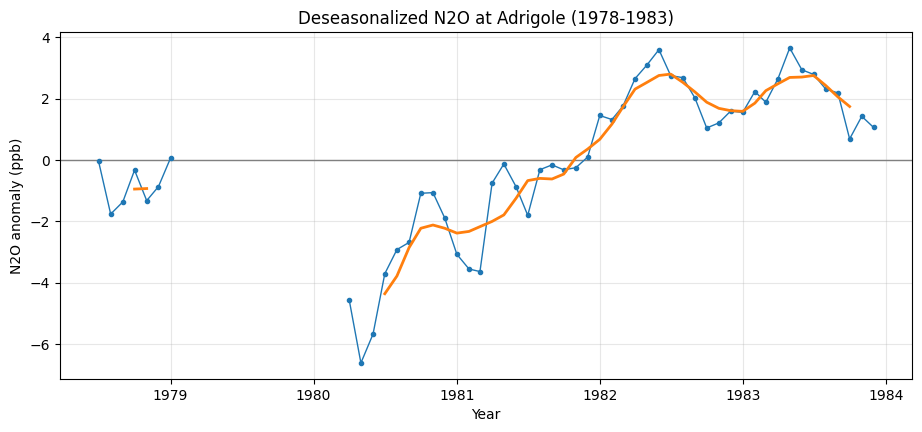

In [12]:
ds_n2o = xr.open_dataset("agage-ale-gcmd_adr_n2o_20260716.nc")
n2o_monthly = ds_n2o["mf"].resample(time="1MS").mean()  # 月平均
n2o_clim = n2o_monthly.groupby("time.month").mean()
n2o_anom = n2o_monthly.groupby("time.month") - n2o_clim  # 去掉季节循环

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axhline(0, color="gray", linewidth=1)
ax.plot(n2o_anom["time"], n2o_anom.values, marker="o", markersize=3, linewidth=1)
ax.plot(n2o_anom["time"], n2o_anom.rolling(time=6, center=True).mean(), linewidth=2)
ax.set_title("Deseasonalized N2O at Adrigole (1978-1983)")
ax.set_xlabel("Year")
ax.set_ylabel("N2O anomaly (ppb)")
ax.grid(alpha=0.3)
plt.show()

#### 3.2 [10 points] Make at least 5 different plots using the dataset.


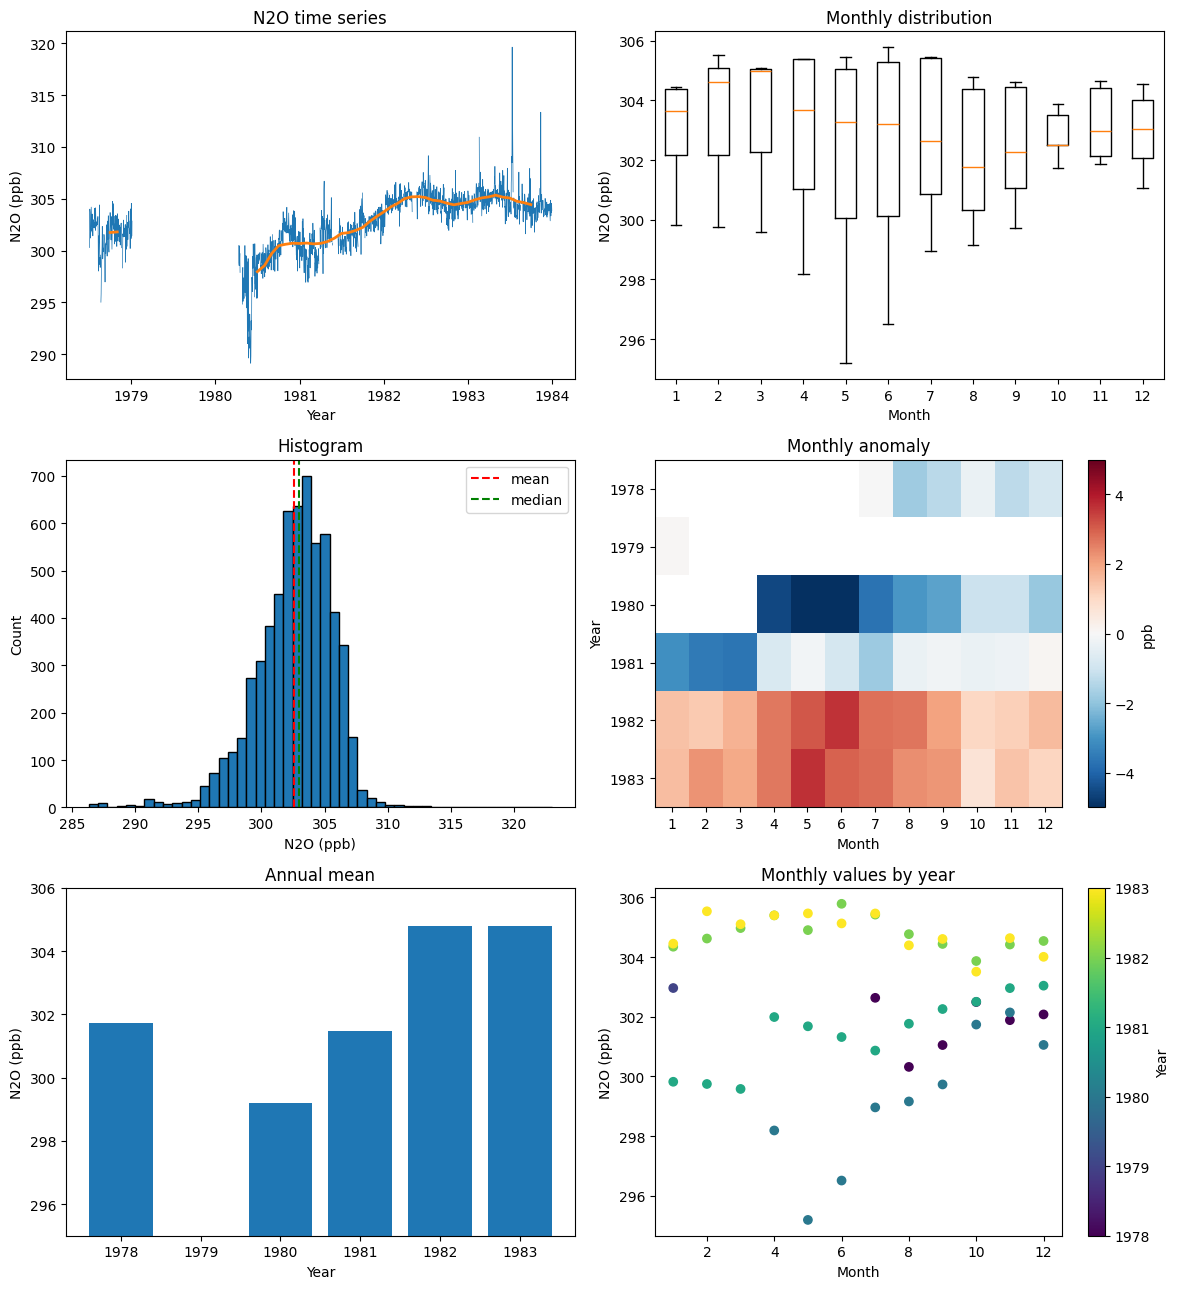

In [13]:
n2o = ds_n2o["mf"].to_series()
daily = n2o.resample("D").mean()  # 日平均，缺测日保留为空
monthly = n2o_monthly.to_series()
anom = n2o_anom.to_series()

fig, axes = plt.subplots(3, 2, figsize=(12, 13))

axes[0, 0].plot(daily.index, daily.values, linewidth=0.5)
axes[0, 0].plot(monthly.index, monthly.rolling(6, center=True).mean(), linewidth=2)
axes[0, 0].set_title("N2O time series")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("N2O (ppb)")

data = [monthly[monthly.index.month == m].dropna().values for m in range(1, 13)]
axes[0, 1].boxplot(data, tick_labels=range(1, 13))
axes[0, 1].set_title("Monthly distribution")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("N2O (ppb)")

axes[1, 0].hist(n2o.values, bins=50, edgecolor="black")
axes[1, 0].axvline(n2o.mean(), color="red", linestyle="--", label="mean")
axes[1, 0].axvline(n2o.median(), color="green", linestyle="--", label="median")
axes[1, 0].set_title("Histogram")
axes[1, 0].set_xlabel("N2O (ppb)")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend()

heat = anom.groupby([anom.index.year, anom.index.month]).mean().unstack()
im = axes[1, 1].imshow(heat.values, aspect="auto", cmap="RdBu_r", vmin=-5, vmax=5)
axes[1, 1].set_title("Monthly anomaly")
axes[1, 1].set_yticks(range(len(heat.index)))
axes[1, 1].set_yticklabels(heat.index)
axes[1, 1].set_xticks(range(12))
axes[1, 1].set_xticklabels(range(1, 13))
axes[1, 1].set_xlabel("Month")
axes[1, 1].set_ylabel("Year")
fig.colorbar(im, ax=axes[1, 1], label="ppb")

annual = monthly.groupby(monthly.index.year).agg(["mean", "count"])
annual = annual[annual["count"] >= 6]
axes[2, 0].bar(annual.index, annual["mean"])
axes[2, 0].set_ylim(295, 306)
axes[2, 0].set_title("Annual mean")
axes[2, 0].set_xlabel("Year")
axes[2, 0].set_ylabel("N2O (ppb)")

sc = axes[2, 1].scatter(monthly.index.month, monthly.values,
                        c=monthly.index.year, cmap="viridis")
axes[2, 1].set_title("Monthly values by year")
axes[2, 1].set_xlabel("Month")
axes[2, 1].set_ylabel("N2O (ppb)")
fig.colorbar(sc, ax=axes[2, 1], label="Year")

fig.tight_layout()
plt.show()